# Uploaded histories: cleaning, season-aware enrichment, EDA and model reruns

This notebook analyses real retained uploads and freshly rerun eligible FBref models. It keeps uploaded Transfermarkt histories separate from learned features. Proposed cross-source identities, retrospective reported prices and source publication dates are not verified. The enrichment is a review dataset, not an authorized model-training dataset.

In [1]:
from pathlib import Path
import os, sys, json
ROOT = Path.cwd()
while not (ROOT/'src/config.py').exists():
    if ROOT == ROOT.parent: raise RuntimeError('Run inside the repository')
    ROOT = ROOT.parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import pandas as pd
import numpy as np
from IPython.display import display, Markdown, Image
from scripts.salimt_history_audit import sha
from src.config import PLAY_STYLES, FEATURE_COLS
from src.data.source_rights import require_model_data_use, SourceUseRestricted
report=json.loads((ROOT/'reports/enrichment/pipeline.json').read_text())
for name, digest in {**report['preserved_input_sha256'], **report['outputs_sha256'], **report['code_sha256']}.items():
    assert sha(ROOT/name)==digest, name
tables={name:pd.read_parquet(ROOT/f'data/processed/real/collected_enrichment_{name}.parquet') for name in report['counts']}
stints=tables['player_club_seasons']; seasons=tables['player_seasons']; events=tables['transfers']
display(pd.Series(report['counts'], name='rows').to_frame())
display(Markdown('Dataset version: `'+report['dataset_version']+'`; source-code commit: `'+report['git_commit']+'`.'))


,rows
player_club_seasons,8252
player_seasons,8043
transfers,365920
spain_transfer_context,8665
integration_review,3378
reported_price_context,8043


Dataset version: `0627515042a64840c7a63c2fef200a0cf9cf317d3105b2d7c0fdb7279f8e50c8`; source-code commit: `b36b97f6a620f4a2dd54b1551b5f9df023ce5ea5`.

## Identity, duplicates and temporal scope

The source key is `(Transfermarkt player ID, season, competition, club)` for statistics. Club stints are aggregated only within the same player, league and season. Any unknown stint value leaves the corresponding season total unknown; rates require positive observed minutes. Exact transfer duplicates are removed using the ten original fields and their original row numbers are retained as lineage. Loan and loan-return events remain distinct. FBref joins use proposed entity mappings plus exact season and league and preserve every original observation. These mappings still require review. Current position and club/profile fields do not establish historical roles or club membership.

In [2]:
display(pd.DataFrame([{
    'base_FBref_observations': report['base_fbref_rows'],
    'same_season_proposed_enrichment_rows': report['joined_fbref_observations'],
    'identity_links_approved': report['approved_identity_links'],
    'exact_transfer_duplicates_removed': report['transfer_exact_duplicates_removed'],
    'budget_eligible_records': report['eligible_historical_budgets']}]))
assert not seasons.duplicated(['source_player_id','season','league']).any()
assert tables['integration_review'].observation_id.is_unique
assert not tables['reported_price_context'].historical_budget_eligible.any()
display(pd.read_csv(ROOT/'reports/enrichment/season_quality.csv'))
agreement=pd.read_csv(ROOT/'reports/enrichment/cross_source_agreement.csv')
comparison=[]
for fb, tm, label in [('minutes','minutes_played','minutes'),('gls','goals','goals'),('ast','assists','assists')]:
    available=agreement.dropna(subset=[fb,'salimt_'+tm])
    comparison.append({'measurement':label,'comparable_proposed_rows':len(available),'equal_reported_values':int(available[fb].eq(available['salimt_'+tm]).sum())})
display(pd.DataFrame(comparison))
display(Markdown('Agreement is a join/provider diagnostic, not identity accuracy. Different minute totals make it unsafe to derive rates by combining FBref counts with uploaded minutes. No source value replaces a FBref observation.'))


,base_FBref_observations,same_season_proposed_enrichment_rows,identity_links_approved,exact_transfer_duplicates_removed,budget_eligible_records
0,3378,2757,0,37,0


,season,league,rows,people,minutes_missing,eligible_minutes,multi_club,inconsistent,outliers
0,2020-2021,La Liga,676,676,379,196,18,0,0
1,2020-2021,Segunda División,731,731,404,230,18,0,0
2,2021-2022,La Liga,713,713,406,190,16,0,0
3,2021-2022,Segunda División,737,737,391,227,23,0,0
4,2022-2023,La Liga,689,689,383,197,15,0,0
5,2022-2023,Segunda División,732,732,389,235,24,0,0
6,2023-2024,La Liga,685,685,380,197,17,0,0
7,2023-2024,Segunda División,707,707,380,227,31,0,0
8,2024-2025,La Liga,683,683,378,202,14,0,0
9,2024-2025,Segunda División,717,717,367,222,21,0,0


,measurement,comparable_proposed_rows,equal_reported_values
0,minutes,1427,164
1,goals,2542,2520
2,assists,2757,2538


Agreement is a join/provider diagnostic, not identity accuracy. Different minute totals make it unsafe to derive rates by combining FBref counts with uploaded minutes. No source value replaces a FBref observation.

## Missingness and cleaning decisions

Numeric count/minute parsing preserves raw text. Negative, nonfinite and fractional event counts are flagged and left unknown. Missing minutes are never replaced with zero, appearance count ×90 or global means. Players with no appearances have unknown minutes in this source; the next analysis separates these from missing minutes among players who did appear. Missingness can select the per-90 cohort, so this is not a representative completeness claim.

In [3]:
numeric=['minutes_played','goals','assists','yellow_cards','nb_on_pitch']
display(stints[numeric].isna().agg(['sum','mean']).T)
apps=stints.assign(appearance_band=pd.cut(stints.nb_on_pitch,[-1,0,5,10,20,50]))
display(apps.groupby('appearance_band', observed=True).agg(rows=('player_id','size'),missing_minutes=('minutes_played',lambda x:x.isna().mean())))
display(Markdown(f"Missing stint minutes: **{report['minutes_missing_stints']}**; missing despite reported appearances: **{report['missing_minutes_with_appearances']}**. These rows remain in the descriptive data but cannot supply complete season rates."))


,sum,mean
minutes_played,4731.0,0.573316
goals,506.0,0.061318
assists,0.0,0.000000
yellow_cards,0.0,0.000000
nb_on_pitch,0.0,0.000000


,rows,missing_minutes
appearance_band,,
"(-1, 0]",1311,1.000000
"(0, 5]",1857,0.806677
"(5, 10]",541,0.715342
"(10, 20]",1281,0.539422
"(20, 50]",3262,0.258737


Missing stint minutes: **4731**; missing despite reported appearances: **3420**. These rows remain in the descriptive data but cannot supply complete season rates.

## Distributions, outliers and correlations

Fixed conservative checks flag >6,000 minutes or >60 goals/assists within a league-season stint and internally inconsistent counts. Flagging does not establish an error: rows remain available and no automatic winsorization or global outlier imputation is applied. Descriptive Spearman correlations use pairwise available observations; counts correlate with exposure, and per-90 ratios depend on the minute denominator. G+A is retained for reporting and excluded from model fitting because it repeats goals/assists.

,count,mean,std,min,1%,25%,50%,75%,99%,max
minutes_played,3399.0,982.997646,894.384383,5.000000,65.960000,308.000000,643.000000,1374.500000,3512.080000,3780.000000
goals,7541.0,1.282058,2.687210,0.000000,0.000000,0.000000,0.000000,1.000000,13.000000,31.000000
assists,8043.0,0.874176,1.639958,0.000000,0.000000,0.000000,0.000000,1.000000,7.000000,17.000000
gls_p90,2903.0,1.062565,2.237717,0.024732,0.028356,0.095796,0.322196,0.975169,11.245144,29.680851
ast_p90,3399.0,0.333610,0.702317,0.000000,0.000000,0.000000,0.078329,0.360000,3.253110,11.250000


,invalid
nb_in_group_invalid,0
nb_on_pitch_invalid,0
goals_invalid,0
assists_invalid,0
own_goals_invalid,0
subed_in_invalid,0
subed_out_invalid,0
yellow_cards_invalid,0
second_yellow_cards_invalid,0
direct_red_cards_invalid,0


inconsistent_counts      0
outlier_rows_retained    0
dtype: int64

,league,season,field,development_IQR_low,development_IQR_high,observed,outside_development_IQR,policy
0,La Liga,2020-2021,minutes_played,-1198.750000,3903.250000,196,0,descriptive flag only; no deletion or winsoriz...
1,La Liga,2021-2022,minutes_played,-1198.750000,3903.250000,190,0,descriptive flag only; no deletion or winsoriz...
2,La Liga,2022-2023,minutes_played,-1198.750000,3903.250000,197,0,descriptive flag only; no deletion or winsoriz...
3,La Liga,2023-2024,minutes_played,-1198.750000,3903.250000,197,0,descriptive flag only; no deletion or winsoriz...
4,La Liga,2024-2025,minutes_played,-1198.750000,3903.250000,202,0,descriptive flag only; no deletion or winsoriz...
5,La Liga,2020-2021,gls_p90,-0.310864,0.660203,166,11,descriptive flag only; no deletion or winsoriz...
6,La Liga,2021-2022,gls_p90,-0.310864,0.660203,163,7,descriptive flag only; no deletion or winsoriz...
7,La Liga,2022-2023,gls_p90,-0.310864,0.660203,166,8,descriptive flag only; no deletion or winsoriz...
8,La Liga,2023-2024,gls_p90,-0.310864,0.660203,171,13,descriptive flag only; no deletion or winsoriz...
9,La Liga,2024-2025,gls_p90,-0.310864,0.660203,169,12,descriptive flag only; no deletion or winsoriz...


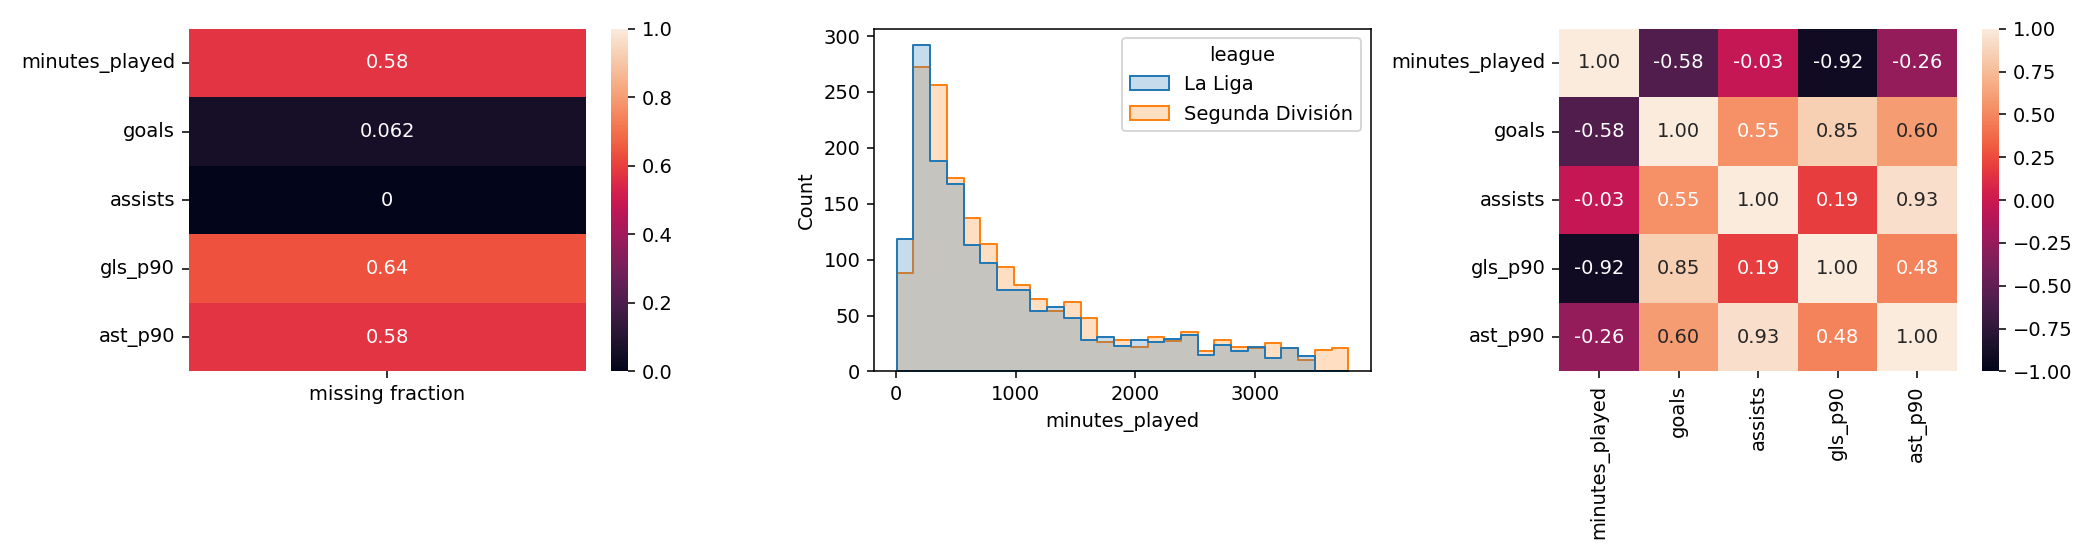

In [4]:
display(seasons[['minutes_played','goals','assists','gls_p90','ast_p90']].describe(percentiles=[.01,.25,.5,.75,.99]).T)
display(stints[[c for c in stints if c.endswith('_invalid')]].sum().rename('invalid').to_frame())
display(pd.Series({'inconsistent_counts':report['count_inconsistencies'],'outlier_rows_retained':report['outlier_rows_retained']}))
display(pd.read_csv(ROOT/'reports/enrichment/distribution_tail_flags.csv'))
display(Image(filename=str(ROOT/'reports/enrichment/quality_distributions_correlations.png')))


## League, season and position comparisons

2025/26 is a partial source snapshot and cannot be compared with completed seasons as final production. The minute floor is applied after all club stints have been aggregated. Position comparisons below use the uploaded current profile label: they are descriptive metadata groupings, not verified historical tactical roles. Large differences in availability between leagues or seasons should be investigated before league-wide recommendation claims.

rows  median_observed_minutes  \
season    league                                            
2020-2021 La Liga            676                    717.0   
          Segunda División   731                    733.0   
2021-2022 La Liga            713                    646.0   
          Segunda División   737                    762.0   
2022-2023 La Liga            689                    683.5   
          Segunda División   732                    736.0   
2023-2024 La Liga            685                    657.0   
          Segunda División   707                    858.0   
2024-2025 La Liga            683                    631.0   
          Segunda División   717                    602.5   
2025-2026 La Liga            468                    236.0   
          Segunda División   505                    216.5   

                            median_observed_goals  eligible_450_minutes  
season    league                                                         
2020-2021 La Liga                             0.0                   196  
          Segunda División                    0.0                   230  
2021-2022 La Liga                             0.0                   190  
          Segunda División                    0.0                   227  
2022-2023 La Liga                             0.0                   197  
          Segunda División                    0.0                   235  
2023-2024 La Liga                             0.0                   197  
          Segunda División                    0.0                   227  
2024-2025 La Liga                             0.0                   202  
          Segunda División                    0.0                   222  
2025-2026 La Liga                             0.0                     0  
          Segunda División                    0.0                     1

,rows,missing_minutes
position_source,,
Defender - Centre-Back,1415,0.695406
Midfield - Central Midfield,1201,0.617818
Attack - Centre-Forward,1065,0.391549
Goalkeeper,921,0.450597
Attack - Left Winger,703,0.469417
Defender - Right-Back,687,0.711790
Attack - Right Winger,670,0.502985
Defender - Left-Back,626,0.742812
Midfield - Attacking Midfield,454,0.517621


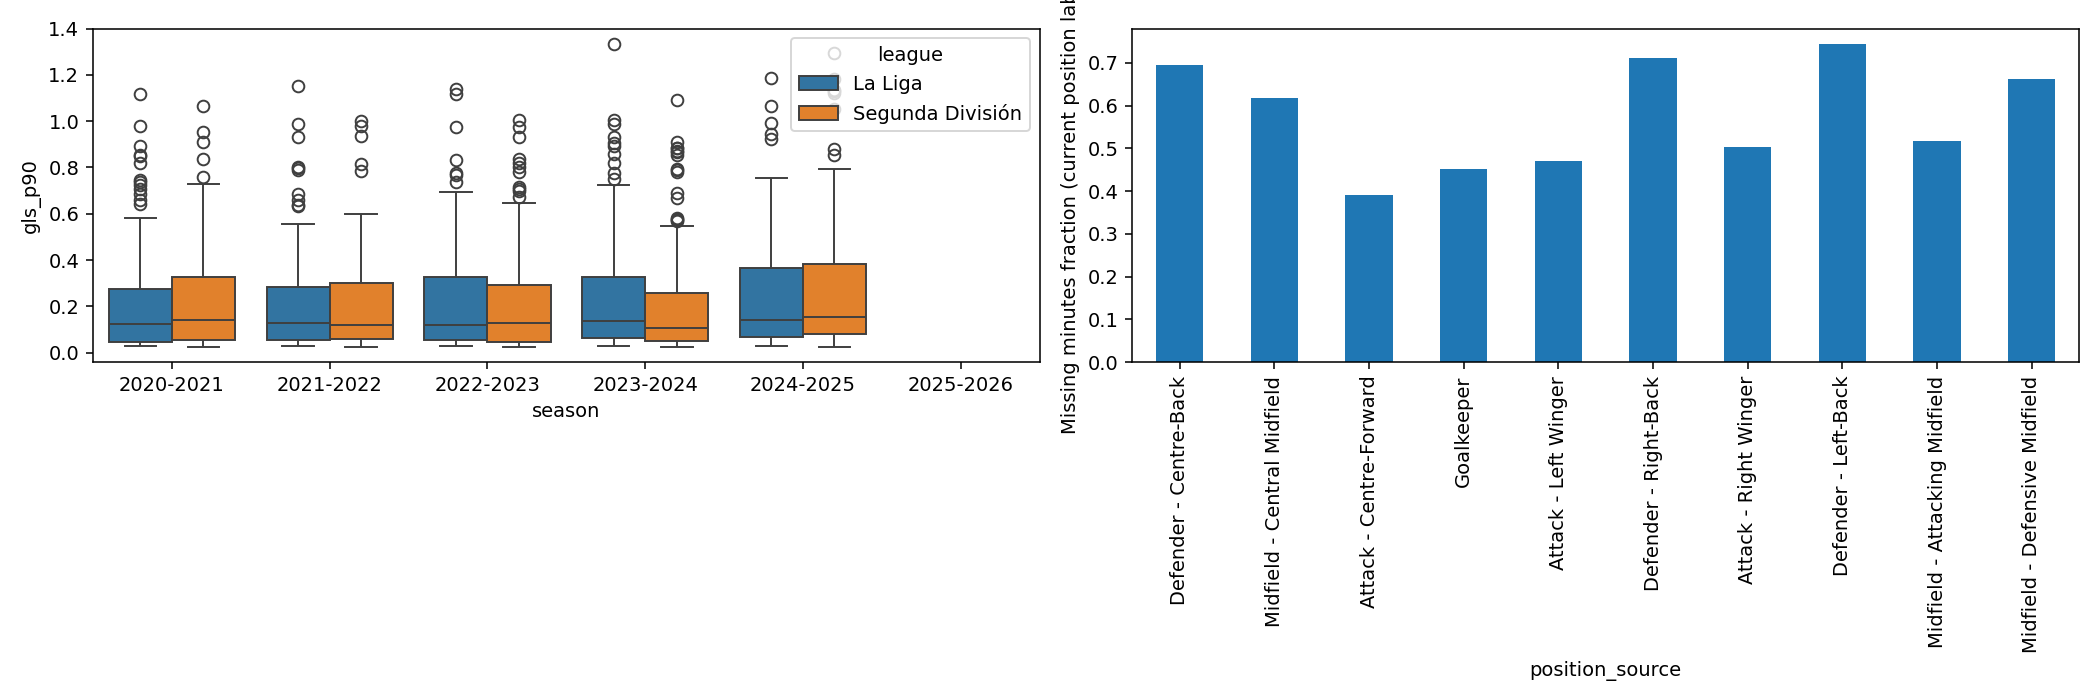

,season,league,gls_p90,ast_p90,ga_p90,sh_p90,sot_p90,crs_p90,int_p90,tklw_p90,fls_p90,fld_p90
0,2020-2021,La Liga,257,297,257,0,0,0,0,0,0,0
1,2020-2021,Segunda División,277,327,277,0,0,0,0,0,0,0
2,2021-2022,La Liga,264,307,264,0,0,0,0,0,0,0
3,2021-2022,Segunda División,297,346,297,0,0,0,0,0,0,0
4,2022-2023,La Liga,264,306,264,0,0,0,0,0,0,0
5,2022-2023,Segunda División,295,343,295,0,0,0,0,0,0,0
6,2023-2024,La Liga,260,305,260,0,0,0,0,0,0,0
7,2023-2024,Segunda División,285,327,285,0,0,0,0,0,0,0
8,2024-2025,La Liga,260,305,260,0,0,0,0,0,0,0
9,2024-2025,Segunda División,306,350,306,0,0,0,0,0,0,0


Original six styles remain: posesion, presion_alta, vertical, contraataque, solidez_defensiva, desborde_banda, finisher, creator. The uploaded source lacks shots, shots on target, crosses, interceptions, tackles won and foul statistics; it cannot independently support the full style contract.

In [5]:
display(seasons.groupby(['season','league']).agg(rows=('source_player_id','size'),median_observed_minutes=('minutes_played','median'),median_observed_goals=('goals','median'),eligible_450_minutes=('minutes_eligible','sum')))
display(stints.groupby('position_source').agg(rows=('player_id','size'),missing_minutes=('minutes_played',lambda x:x.isna().mean())).sort_values('rows',ascending=False).head(15))
display(Image(filename=str(ROOT/'reports/enrichment/season_league_position_comparison.png')))
display(pd.read_csv(ROOT/'reports/enrichment/mandatory_feature_coverage.csv'))
display(Markdown('Original six styles remain: '+', '.join(PLAY_STYLES)+'. The uploaded source lacks shots, shots on target, crosses, interceptions, tackles won and foul statistics; it cannot independently support the full style contract.'))


## Transfers and valuation context

Reported positive numerical fees are distinct from market values. A numerical zero does not prove a free transfer, including for loans. Date/season conflicts are flagged rather than rewritten; the source season label is retained. The most recent reported valuation on/before season-end can be associated within this source for auditing only. Unknown publication dates, unverified identities and source-use status prevent this association from becoming a historical scouting budget. No future valuation is backfilled into earlier seasons.

In [6]:
display(events.groupby(['transfer_type','fee_semantics']).size().rename('events').to_frame())
display(pd.Series({'ambiguous_zero_fee_events':report['ambiguous_zero_fee_events'],'date_season_conflicts':report['transfer_season_date_conflicts']}))
prices=tables['reported_price_context']
display(prices.groupby(['season','league']).agg(rows=('source_player_id','size'),reported_values=('reported_value_eur_not_budget','count'),reported_zero_values=('zero_value_ambiguous','sum')))
assert (prices.reported_value_date.dropna()<=prices.loc[prices.reported_value_date.notna(),'report_cutoff']).all()
display(pd.Series(report['model_input_rejections'],name='model_input_rejection').to_frame())


events
transfer_type    fee_semantics                            
Draft            unknown_or_zero_not_verified_free     285
Loan             unknown_or_zero_not_verified_free   42131
Return from loan unknown_or_zero_not_verified_free   43326
Transfer         positive_numeric_reported           12359
                 unknown_or_zero_not_verified_free  267819

ambiguous_zero_fee_events    353561
date_season_conflicts          2282
dtype: int64

rows  reported_values  reported_zero_values
season    league                                                       
2020-2021 La Liga            676              654                     5
          Segunda División   731              647                    11
2021-2022 La Liga            713              675                     9
          Segunda División   737              669                    16
2022-2023 La Liga            689              663                     8
          Segunda División   732              682                    15
2023-2024 La Liga            685              667                     8
          Segunda División   707              662                    23
2024-2025 La Liga            683              668                     4
          Segunda División   717              679                    17
2025-2026 La Liga            468              465                     4
          Segunda División   505              488                     1

,model_input_rejection
player_club_seasons,Transfermarkt model use blocked: terms section...
player_seasons,Transfermarkt model use blocked: terms section...
transfers,Transfermarkt model use blocked: terms section...
spain_transfer_context,Transfermarkt model use blocked: terms section...
integration_review,Unreviewed cross-source identity links cannot ...
reported_price_context,Transfermarkt model use blocked: terms section...


## Fresh eligible real-data experiments and validation

Three models are refitted from the unchanged eligible FBref cohorts using the existing pipeline, with transformations fitted only on training seasons. New uploaded fields are excluded by the actual source and identity guards. Validation chooses the distance method; holdout remains chronological and frozen. Baselines include goals, goals+assists and seeded random ranking. These metrics measure next-season same-player profile retrieval, not scouting relevance or transfer success. The rerun tests reproducibility; it cannot demonstrate gains from blocked enrichment.

### offensive: validation-selected `euclidean_profile`

,phase,method,queries,candidate_count,mrr,mrr_ci_low,mrr_ci_high,recall_at_5,recall_at_10,selected_on_validation
0,validation,cluster_cosine,249,393,0.062297,0.047349,0.083121,0.088353,0.140562,False
1,validation,cosine_profile,249,393,0.061137,0.046493,0.081683,0.076305,0.136546,False
2,validation,euclidean_profile,249,393,0.065250,0.049352,0.086667,0.080321,0.144578,True
3,validation,goals_assists,249,393,0.039363,0.029536,0.052754,0.046768,0.081487,False
4,validation,goals_only,249,393,0.024841,0.021849,0.029139,0.014628,0.045320,False
5,validation,pca2_cosine,249,393,0.040091,0.028233,0.053375,0.040161,0.080321,False
6,validation,pca2_euclidean,249,393,0.043130,0.035177,0.053050,0.052209,0.108434,False
7,validation,pca4_cosine,249,393,0.056002,0.041708,0.072977,0.052209,0.116466,False
8,validation,pca4_euclidean,249,393,0.061588,0.046023,0.079445,0.080321,0.152610,False
9,validation,random,249,393,0.019657,0.012499,0.029576,0.012048,0.024096,False


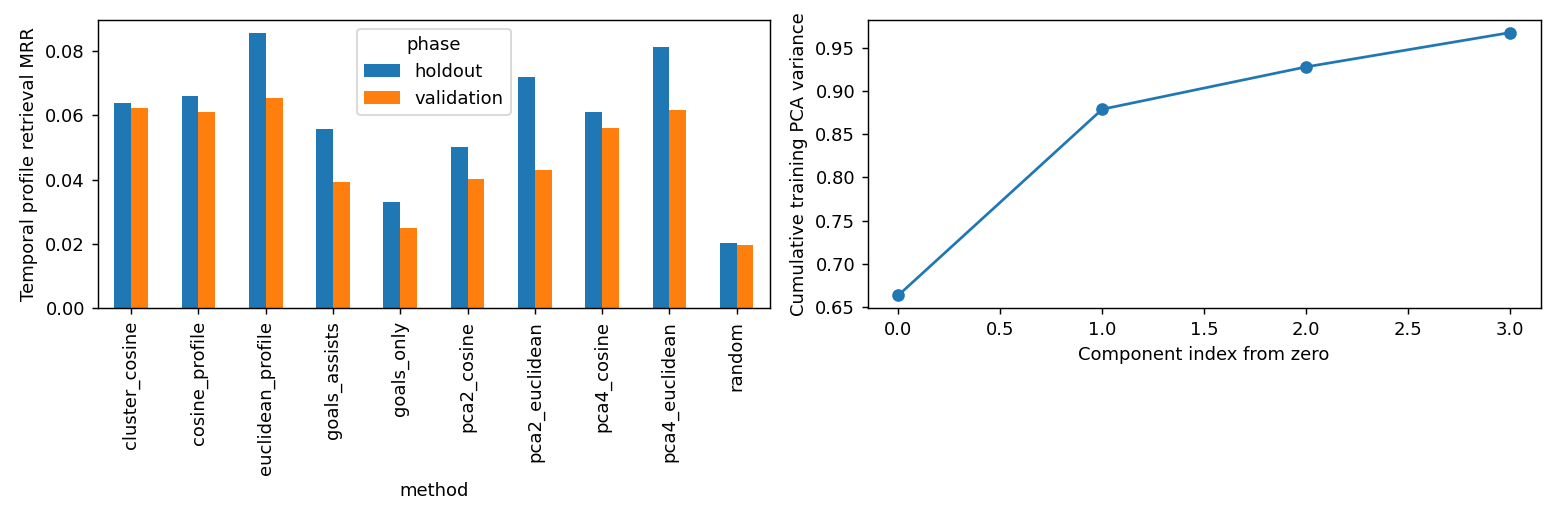

### core: validation-selected `euclidean_profile`

,phase,method,queries,candidate_count,mrr,mrr_ci_low,mrr_ci_high,recall_at_5,recall_at_10,selected_on_validation
0,validation,cluster_cosine,248,388,0.196910,0.156091,0.234158,0.270161,0.387097,False
1,validation,cosine_profile,248,388,0.200570,0.159329,0.238283,0.274194,0.395161,False
2,validation,euclidean_profile,248,388,0.227642,0.183754,0.265669,0.310484,0.403226,True
3,validation,goals_assists,248,388,0.035116,0.025322,0.048120,0.041818,0.063476,False
4,validation,goals_only,248,388,0.035855,0.023696,0.050169,0.038978,0.061828,False
5,validation,pca2_cosine,248,388,0.054564,0.044607,0.069592,0.064516,0.125000,False
6,validation,pca2_euclidean,248,388,0.102825,0.081220,0.128653,0.137097,0.237903,False
7,validation,pca4_cosine,248,388,0.138072,0.109831,0.172795,0.193548,0.306452,False
8,validation,pca4_euclidean,248,388,0.171421,0.140828,0.208954,0.241935,0.322581,False
9,validation,random,248,388,0.016833,0.011182,0.023053,0.016129,0.024194,False


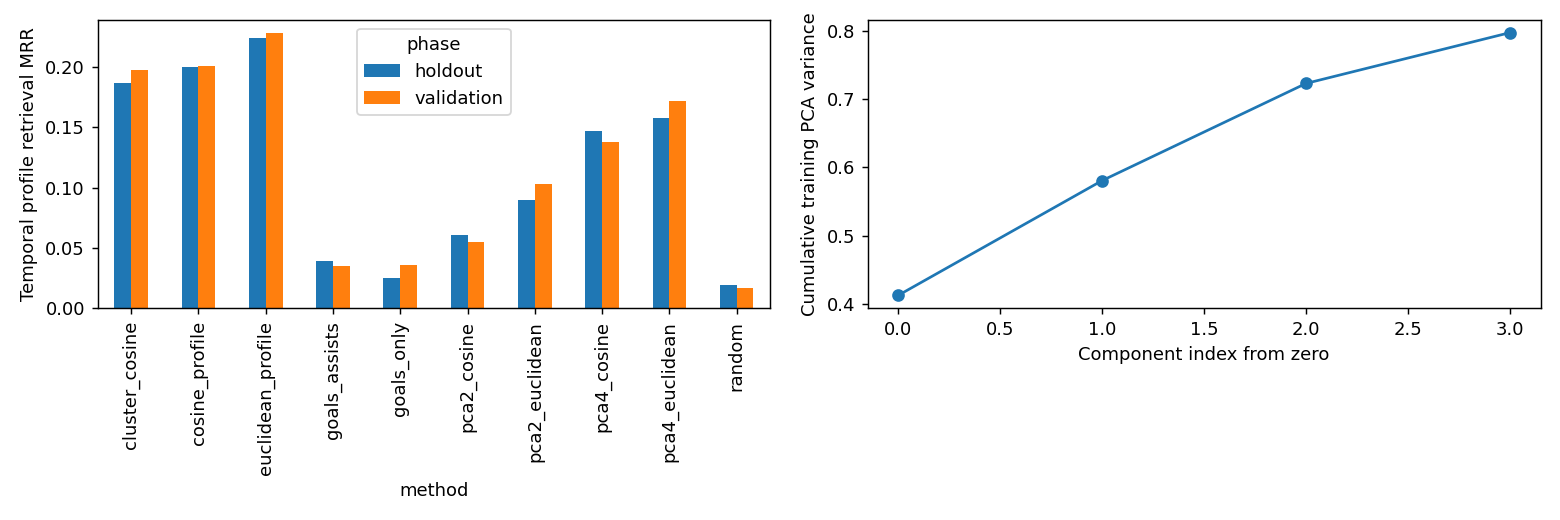

### attack_on_core: validation-selected `euclidean_profile`

,phase,method,queries,candidate_count,mrr,mrr_ci_low,mrr_ci_high,recall_at_5,recall_at_10,selected_on_validation
0,validation,cluster_cosine,248,388,0.061314,0.046836,0.079837,0.076613,0.141129,False
1,validation,cosine_profile,248,388,0.059544,0.046096,0.077738,0.072581,0.129032,False
2,validation,euclidean_profile,248,388,0.078611,0.055803,0.101289,0.104839,0.197581,True
3,validation,goals_assists,248,388,0.035116,0.025322,0.048120,0.041818,0.063476,False
4,validation,goals_only,248,388,0.035855,0.023696,0.050169,0.038978,0.061828,False
5,validation,pca2_cosine,248,388,0.034808,0.027321,0.044318,0.028226,0.068548,False
6,validation,pca2_euclidean,248,388,0.053693,0.043030,0.064370,0.080645,0.141129,False
7,validation,pca4_cosine,248,388,0.053832,0.041025,0.070344,0.048387,0.108871,False
8,validation,pca4_euclidean,248,388,0.066623,0.048976,0.084151,0.092742,0.161290,False
9,validation,random,248,388,0.016833,0.011182,0.023053,0.016129,0.024194,False


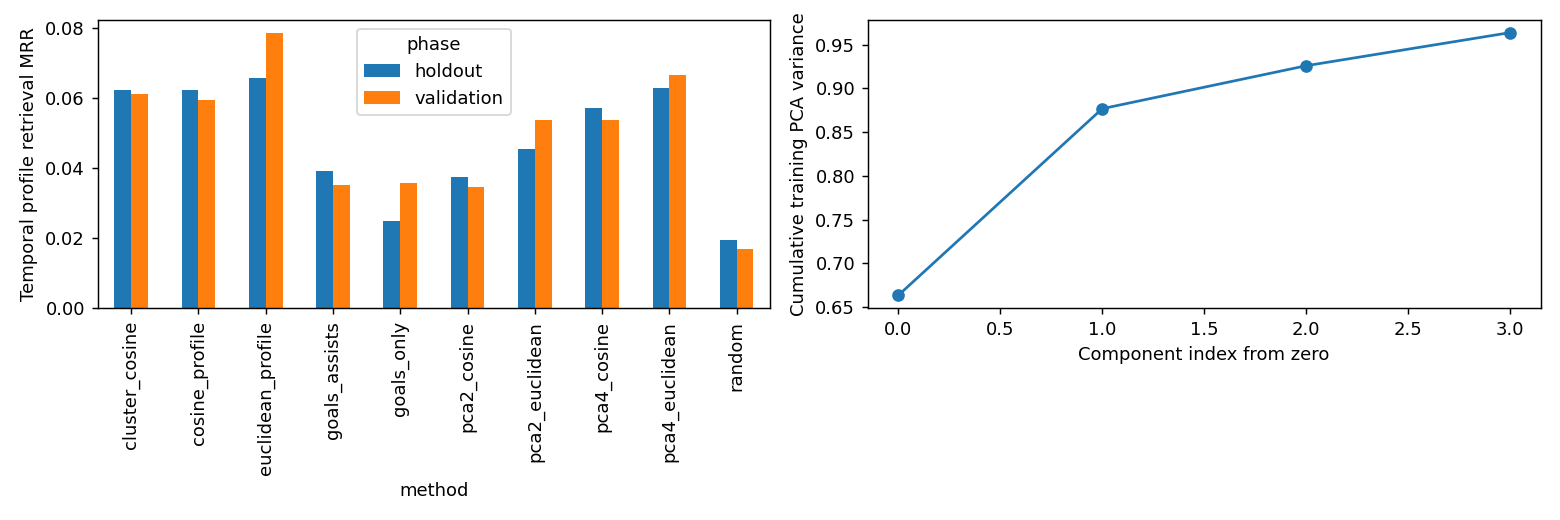

Rerun holdout MRR matches the original experiments. No new-data improvement is claimed.

In [7]:
original=json.loads((ROOT/'reports/collected_model_results.json').read_text())
for name, info in report['new_model_experiments'].items():
    scores=pd.read_csv(ROOT/f'reports/enrichment/{name}_retrieval.csv')
    display(Markdown(f"### {name}: validation-selected `{info['selected_method']}`"))
    display(scores[['phase','method','queries','candidate_count','mrr','mrr_ci_low','mrr_ci_high','recall_at_5','recall_at_10','selected_on_validation']])
    np.testing.assert_allclose(info['holdout_mrr'],original['experiments'][name]['holdout_metrics']['mrr'])
    display(Image(filename=str(ROOT/f'reports/enrichment/{name}_evaluation.png')))
display(Markdown('Rerun holdout MRR matches the original experiments. No new-data improvement is claimed.'))


## PCA, K-means, robustness and recommendations

PCA loadings describe training covariance with arbitrary sign; they are not tactical roles. K-means cluster count is selected on training silhouette and differs conceptually from the six expert style directions. Seed agreement does not validate role accuracy. A hard cluster gate can exclude useful neighbours, so it is compared with unrestricted distance models. Training-row bootstrap shortlist overlap assesses sensitivity; it is not relevance accuracy. Earlier extended validation also found instability around core PC4, so interpretation of that component remains limited.

In [8]:
for name, info in report['new_model_experiments'].items():
    display(Markdown('### '+name))
    display(pd.DataFrame([{'k':info['selected_k'],'first_two_PCA_variance':sum(info['pca_explained_variance'][:2]),'first_four_PCA_variance':sum(info['pca_explained_variance']),'bootstrap_top5_Jaccard':info['robustness_top5_jaccard_mean'],**info['cluster_diagnostics']}]))
    display(pd.read_csv(ROOT/f'reports/enrichment/{name}_pca_loadings.csv'))
    display(pd.read_csv(ROOT/f'reports/enrichment/{name}_cluster_centroids.csv'))
    display(pd.read_csv(ROOT/f'reports/enrichment/{name}_shortlists.csv').groupby('position').agg(recommendations=('entity_id','size'),references=('reference_entity','nunique')))


### offensive

,k,first_two_PCA_variance,first_four_PCA_variance,bootstrap_top5_Jaccard,position_nmi,season_nmi,seed_ari_mean
0,2,0.878755,0.967394,0.994444,0.343962,0.000735,1.0


,gls_p90,ast_p90,sh_p90,sot_p90,xg_p90,xag_p90
0,0.435647,0.268886,0.458529,0.467641,0.455462,0.318637
1,-0.254173,0.678729,-0.141184,-0.181379,-0.248926,0.599940
2,0.634103,0.333742,-0.569412,-0.256772,0.199646,-0.237717
3,0.266385,-0.596240,-0.260690,-0.154705,0.033534,0.693195


,cluster,gls_p90,ast_p90,sh_p90,sot_p90,xg_p90,xag_p90
0,0,1.156575,0.656370,1.215153,1.245618,1.205396,0.821709
1,1,-0.464549,-0.263637,-0.488077,-0.500314,-0.484158,-0.330046


,recommendations,references
position,,
DF,5,1
FW,5,1
MF,5,1


...

### attack_on_core

,k,first_two_PCA_variance,first_four_PCA_variance,bootstrap_top5_Jaccard,position_nmi,season_nmi,seed_ari_mean
0,2,0.87689,0.963878,0.972222,0.329853,0.00022,0.996892


,gls_p90,ast_p90,sh_p90,sot_p90,xg_p90,xag_p90
0,0.435035,0.281097,0.455173,0.464363,0.454651,0.319696
1,-0.254386,0.668544,-0.147315,-0.203587,-0.240652,0.606032
2,0.646052,0.285041,-0.608150,-0.237539,0.193500,-0.194048
3,0.226374,-0.626592,-0.217615,-0.129143,0.027673,0.700954


,cluster,gls_p90,ast_p90,sh_p90,sot_p90,xg_p90,xag_p90
0,0,-0.459864,-0.307253,-0.490094,-0.498376,-0.480768,-0.350581
1,1,1.109201,0.741100,1.182115,1.202091,1.159622,0.845607


,recommendations,references
position,,
DF,5,1
FW,5,1
MF,5,1


## MLflow and completed versus blocked work

Completed: numeric cleaning with raw preservation; safe season aggregation; exact-event deduplication; source-separated profile and valuation associations; proposed season-aware FBref enrichment; executable EDA; three eligible real-data model refits with baselines, uncertainty and robustness artifacts. Partial: fee semantics, identity validation and historical positional context. Blocked: new source fields entering model fitting until the existing source-use and identity requirements are resolved. No valuation model or transfer-success claim is invented.

In [9]:
for name, info in report['new_model_experiments'].items():
    record=json.loads((ROOT/f'reports/enrichment/mlflow_export/{name}/run.json').read_text())
    assert record['status']=='FINISHED' and record['run_id']==info['mlflow_run_id']
    display(pd.DataFrame([{'model':name,'MLflow_run':record['run_id'],'status':record['status'],'downloaded_artifacts':info['exported_artifacts'],'real_dataset':record['tags']['dataset_kind']}]))
display(Markdown('; '.join(report['limits'])))


,model,MLflow_run,status,downloaded_artifacts,real_dataset
0,offensive,4a7865822b254c8c8b6b606b491a4e65,FINISHED,13,real_fbref_only_enrichment_excluded


,model,MLflow_run,status,downloaded_artifacts,real_dataset
0,core,837dc6ff27654c6eb41ef5df720d28db,FINISHED,13,real_fbref_only_enrichment_excluded


,model,MLflow_run,status,downloaded_artifacts,real_dataset
0,attack_on_core,81c82c5ce15b41139eed6adb99dcd670,FINISHED,13,real_fbref_only_enrichment_excluded


No Transfermarkt-derived fields entered fitting or transformation.; Cross-source joins are proposals, not verified identity labels.; Reported-date valuation context is not a budget price or historical availability proof.; Advanced mandatory features absent in uploaded source; 2025/26 partial.; Model metrics are temporal profile retrieval, not transfer-success validation.